# 03 | Prepare predictors and study model sensitivity

This stage builds a binary outcome from the exam score, exposes a direct label-leakage pitfall, then compares alternative preparation strategies. Every experiment retains the same data values, splits and hyperparameters as the workflow.

**Key rule:** the final score and grade are used only to construct the target. They must be removed from the predictors for a genuine early-support model.


In [1]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import plotly.express as px
%matplotlib inline

In [2]:
sd = pd.read_csv("data/student_habits_performance.csv")
sd.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 16 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   student_key               1000 non-null   str    
 1   age_years                 1000 non-null   int64  
 2   gender_group              1000 non-null   str    
 3   study_time_daily          1000 non-null   float64
 4   social_media_time         1000 non-null   float64
 5   netflix_viewing_hours     1000 non-null   float64
 6   part_time_employment      1000 non-null   str    
 7   attendance_rate           1000 non-null   float64
 8   sleep_duration_hours      1000 non-null   float64
 9   diet_category             1000 non-null   str    
 10  exercise_days_weekly      1000 non-null   int64  
 11  parental_schooling_tier   909 non-null    str    
 12  internet_access_quality   1000 non-null   str    
 13  mental_wellbeing_score    1000 non-null   int64  
 14  extracurricular_acti

## Define the grade conversion

Apply the A–F score thresholds to `exam_result`. The conversion is used only to construct the classification target; the thresholds are not tuned or revised.


In [3]:
def convert_to_letter_grade(score):
    if score >= 80:
        return 'A'
    elif score >= 70:
        return 'B'
    elif score >= 60:
        return 'C'
    elif score >= 50:
        return 'D'
    else:
        return 'F'

# Create 'grade' attribute.
sd['grade'] = sd['exam_result'].apply(convert_to_letter_grade)
sd.head()

,student_key,age_years,gender_group,study_time_daily,social_media_time,netflix_viewing_hours,part_time_employment,attendance_rate,sleep_duration_hours,diet_category,exercise_days_weekly,parental_schooling_tier,internet_access_quality,mental_wellbeing_score,extracurricular_activity,exam_result,grade
0,S1000,23,Female,0.0,1.2,1.1,No,85.0,8.0,Fair,6,Master,Average,8,Yes,56.2,D
1,S1001,20,Female,6.9,2.8,2.3,No,97.3,4.6,Good,6,High School,Average,8,No,100.0,A
2,S1002,21,Male,1.4,3.1,1.3,No,94.8,8.0,Poor,1,High School,Poor,1,No,34.3,F
3,S1003,23,Female,1.0,3.9,1.0,No,71.0,9.2,Poor,4,Master,Good,1,Yes,26.8,F
4,S1004,19,Female,5.0,4.4,0.5,No,90.9,4.9,Fair,3,Master,Good,1,No,66.4,C


In [4]:
print(sd['grade'].unique())
grade_counts = sd['grade'].value_counts().sort_index()
print(grade_counts)

<StringArray>
['D', 'A', 'F', 'C', 'B']
Length: 5, dtype: str
grade
A    277
B    234
C    209
D    149
F    131
Name: count, dtype: int64


## Construct the binary outcome

Grades **D/F** become `AtRisk`, while **A–C** become `NotAtRisk`. These category values are retained unchanged so that comparisons against the models remain meaningful.


In [5]:
# Create risk_status attribute.
sd['risk_status'] = sd['grade'].apply(lambda x: 'AtRisk' if x in ['D', 'F'] else 'NotAtRisk')
sd.head()

,student_key,age_years,gender_group,study_time_daily,social_media_time,netflix_viewing_hours,part_time_employment,attendance_rate,sleep_duration_hours,diet_category,exercise_days_weekly,parental_schooling_tier,internet_access_quality,mental_wellbeing_score,extracurricular_activity,exam_result,grade,risk_status
0,S1000,23,Female,0.0,1.2,1.1,No,85.0,8.0,Fair,6,Master,Average,8,Yes,56.2,D,AtRisk
1,S1001,20,Female,6.9,2.8,2.3,No,97.3,4.6,Good,6,High School,Average,8,No,100.0,A,NotAtRisk
2,S1002,21,Male,1.4,3.1,1.3,No,94.8,8.0,Poor,1,High School,Poor,1,No,34.3,F,AtRisk
3,S1003,23,Female,1.0,3.9,1.0,No,71.0,9.2,Poor,4,Master,Good,1,Yes,26.8,F,AtRisk
4,S1004,19,Female,5.0,4.4,0.5,No,90.9,4.9,Fair,3,Master,Good,1,No,66.4,C,NotAtRisk


In [6]:
risk_status_counts = sd['risk_status'].value_counts().sort_index()
print(risk_status_counts)

risk_status
AtRisk       280
NotAtRisk    720
Name: count, dtype: int64


### Class balance

The derived labels cover **280 `AtRisk`** and **720 `NotAtRisk`** records. This imbalance motivates class-specific metrics and alternative sampling strategies, rather than reliance on overall accuracy.


## Inspect atypical records

Detect unusual values in the numeric inputs before altering the training distribution. Outlier flags are a diagnostic device; no row is automatically excluded solely because it lies in a tail.


In [ ]:
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.ensemble import IsolationForest
import matplotlib.pyplot as plt

# Inspect unusual observations without altering the source records.
features = ['study_time_daily', 'exam_result', 'sleep_duration_hours', 'social_media_time', 
            'mental_wellbeing_score', 'attendance_rate', 'exercise_days_weekly']

# Read or prepare the relevant input frame.
df = sd[features].dropna()
scaler = StandardScaler()
df_scaled = scaler.fit_transform(df)

# Apply isolation forest.
iso = IsolationForest(contamination=0.025, random_state=42)
outlier_pred = iso.fit_predict(df_scaled)  # Inspect unusual observations without altering the source records.

# Compute the one-component media representation.
pca = PCA(n_components=2)
df_pca = pca.fit_transform(df_scaled)

# Render the current analysis view.
outlier_df = sd.loc[df.index].copy()
outlier_df['PCA1'] = df_pca[:, 0]
outlier_df['PCA2'] = df_pca[:, 1]
outlier_df['outlier_flag'] = outlier_pred

# Inspect unusual observations without altering the source records.
outliers_only = outlier_df[outlier_df['outlier_flag'] == -1]
print(f"Number of outliers detected: {len(outliers_only)}")
print(outliers_only[['exam_result', 'study_time_daily', 'mental_wellbeing_score', 'social_media_time']].to_string())

Number of outliers detected: 25
     exam_result  study_time_daily  mental_wellbeing_score  social_media_time
3           26.8               1.0                       1                3.9
23          43.7               1.1                       1                4.1
92          43.9               0.5                       3                0.8
195         26.7               0.0                       5                2.8
322         96.1               6.1                      10                4.9
411         58.2               1.6                      10                0.8
414         78.7               4.2                       5                5.6
422         29.5               2.0                       2                2.4
431         29.9               0.0                       2                2.0
447         93.6               5.9                       1                0.0
590         42.0               0.0                       7                4.6
630         50.3               0

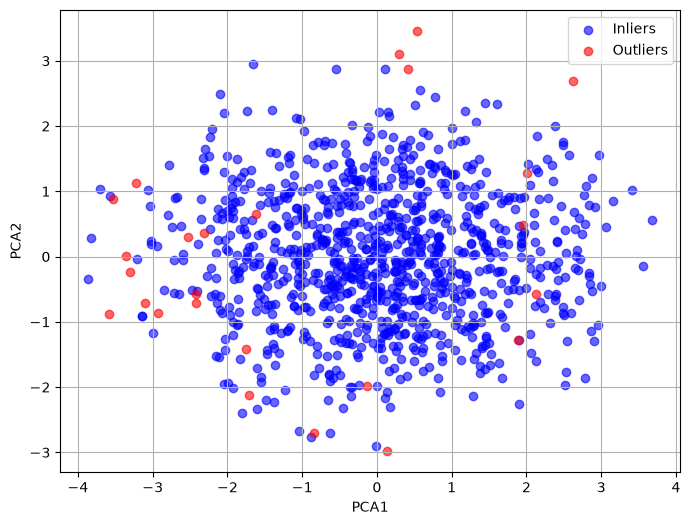

In [8]:
import matplotlib.pyplot as plt

# Configure the chart layout.
plt.figure(figsize=(8, 6))

# Render the current analysis view.
inliers = outlier_df[outlier_df['outlier_flag'] == 1]
plt.scatter(inliers['PCA1'], inliers['PCA2'], 
            c='blue', alpha=0.6, label='Inliers')

# Inspect unusual observations without altering the source records.
outliers = outlier_df[outlier_df['outlier_flag'] == -1]
plt.scatter(outliers['PCA1'], outliers['PCA2'], 
            c='red', alpha=0.6, label='Outliers')

# Keep the target categories consistent across splits.
plt.xlabel('PCA1')
plt.ylabel('PCA2')
plt.grid(True)
plt.legend()

# Configure the chart layout.
plt.savefig('img/outlier_detection_plot.png', format='png')

# Render the current analysis view.
plt.show()


## Establish a leakage-aware baseline

Fit an initial decision tree to expose the consequence of inadvertently including the observed score and its derived grade. Compare its result with a second run that excludes these proxy columns. The first result is intentionally invalid as an early-prediction benchmark.


In [9]:
# Separate the target variable (risk_status) from the feature set.
sd_y = sd['risk_status']
sd_X = sd[sd.columns.difference(['risk_status'])]

In [10]:
from sklearn.preprocessing import OrdinalEncoder

# Keep sd_x as originally defined.
# Make a copy for the following trainings.
sd_XX = sd_X.copy()
# Retrieve the regular numeric columns names.
num_cols = list(sd_XX.select_dtypes(include=['int64','float64']).columns)
# Retrive the regular object columns names.
cat_cols = list(sd_XX.select_dtypes(include=['object']).columns)
# Replace missing/nan values with 0 for numerical columns.
sd_XX[num_cols] = sd_XX[num_cols].apply(lambda col: col.fillna(0, axis=0))
# Replace missing/nan values with '?' for object columns.
sd_XX[cat_cols] = sd_XX[cat_cols].apply(lambda col: col.fillna('?', axis=0).astype(str))
# Use the established encoding for categorical values or labels.
ordinal_encoder = OrdinalEncoder()

sd_XX[cat_cols] = ordinal_encoder.fit_transform(sd_XX[cat_cols])
sd_XX.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 17 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   age_years                 1000 non-null   int64  
 1   attendance_rate           1000 non-null   float64
 2   diet_category             1000 non-null   float64
 3   exam_result               1000 non-null   float64
 4   exercise_days_weekly      1000 non-null   int64  
 5   extracurricular_activity  1000 non-null   float64
 6   gender_group              1000 non-null   float64
 7   grade                     1000 non-null   float64
 8   internet_access_quality   1000 non-null   float64
 9   mental_wellbeing_score    1000 non-null   int64  
 10  netflix_viewing_hours     1000 non-null   float64
 11  parental_schooling_tier   1000 non-null   float64
 12  part_time_employment      1000 non-null   float64
 13  sleep_duration_hours      1000 non-null   float64
 14  social_media_time   

/tmp/ipykernel_314882/1882358359.py:9: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = list(sd_XX.select_dtypes(include=['object']).columns)


In [11]:
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_graphviz
import utils as ad

# Create an instance of the dt classifier leaving.
# All hyperparameters to default values except random_state.
clf = DecisionTreeClassifier(random_state=43)
# Use the established encoding for categorical values or labels.
ad.summarize_stratified_cv(sd_XX, sd_y, clf)

Mean Accuracy is 100.00 +/- 0.00
Mean Precision is 100.00 +/- 0.00
Mean Recall is 100.00 +/- 0.00
Mean F-score is 100.00 +/- 0.00


### Why the first score is perfect

The initial 100% cross-validation accuracy is a **target-leakage artifact**: `exam_result` and `grade` encode the target directly. After removing them, the notebook reports approximately **84.10%** mean accuracy. The lower score is the more informative baseline.


In [12]:
# Remove fields that reveal the outcome directly.
sd_XX = sd_XX.drop(columns=['exam_result', 'grade'])
sd_XX.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 15 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   age_years                 1000 non-null   int64  
 1   attendance_rate           1000 non-null   float64
 2   diet_category             1000 non-null   float64
 3   exercise_days_weekly      1000 non-null   int64  
 4   extracurricular_activity  1000 non-null   float64
 5   gender_group              1000 non-null   float64
 6   internet_access_quality   1000 non-null   float64
 7   mental_wellbeing_score    1000 non-null   int64  
 8   netflix_viewing_hours     1000 non-null   float64
 9   parental_schooling_tier   1000 non-null   float64
 10  part_time_employment      1000 non-null   float64
 11  sleep_duration_hours      1000 non-null   float64
 12  social_media_time         1000 non-null   float64
 13  student_key               1000 non-null   float64
 14  study_time_daily    

In [13]:
ad.summarize_stratified_cv(sd_XX, sd_y, clf)

Mean Accuracy is 84.10 +/- 1.32
Mean Precision is 80.32 +/- 1.65
Mean Recall is 80.12 +/- 1.69
Mean F-score is 80.22 +/- 1.66


## Select usable inputs

Exclude `student_key` because it is an identifier, not an explanatory measurement. Review the remaining columns for relevance, availability at prediction time and potentially misleading relationships.


In [14]:
sd_XX.drop(columns='student_key', inplace=True)
ad.summarize_stratified_cv(sd_XX, sd_y, clf)

Mean Accuracy is 85.00 +/- 2.17
Mean Precision is 81.45 +/- 2.71
Mean Recall is 81.51 +/- 2.33
Mean F-score is 81.45 +/- 2.50


### Check variation before dropping fields

Use descriptive statistics to detect constant columns, implausible ranges and duplicated information. A feature should not be discarded simply because its univariate correlation with the target is small.


In [15]:
sd.describe(include='all')

,student_key,age_years,gender_group,study_time_daily,social_media_time,netflix_viewing_hours,part_time_employment,attendance_rate,sleep_duration_hours,diet_category,exercise_days_weekly,parental_schooling_tier,internet_access_quality,mental_wellbeing_score,extracurricular_activity,exam_result,grade,risk_status
count,1000,1000.0000,1000,1000.00000,1000.000000,1000.000000,1000,1000.000000,1000.000000,1000,1000.000000,909,1000,1000.000000,1000,1000.000000,1000,1000
unique,1000,NaN,3,NaN,NaN,NaN,2,NaN,NaN,3,NaN,3,3,NaN,2,NaN,5,2
top,S1000,NaN,Female,NaN,NaN,NaN,No,NaN,NaN,Fair,NaN,High School,Good,NaN,No,NaN,A,NotAtRisk
freq,1,NaN,481,NaN,NaN,NaN,785,NaN,NaN,437,NaN,392,447,NaN,682,NaN,277,720
mean,NaN,20.4980,NaN,3.55010,2.505500,1.819700,NaN,84.131700,6.470100,NaN,3.042000,NaN,NaN,5.438000,NaN,69.601500,NaN,NaN
std,NaN,2.3081,NaN,1.46889,1.172422,1.075118,NaN,9.399246,1.226377,NaN,2.025423,NaN,NaN,2.847501,NaN,16.888564,NaN,NaN
min,NaN,17.0000,NaN,0.00000,0.000000,0.000000,NaN,56.000000,3.200000,NaN,0.000000,NaN,NaN,1.000000,NaN,18.400000,NaN,NaN
25%,NaN,18.7500,NaN,2.60000,1.700000,1.000000,NaN,78.000000,5.600000,NaN,1.000000,NaN,NaN,3.000000,NaN,58.475000,NaN,NaN
50%,NaN,20.0000,NaN,3.50000,2.500000,1.800000,NaN,84.400000,6.500000,NaN,3.000000,NaN,NaN,5.000000,NaN,70.500000,NaN,NaN
75%,NaN,23.0000,NaN,4.50000,3.300000,2.525000,NaN,91.025000,7.300000,NaN,5.000000,NaN,NaN,8.000000,NaN,81.325000,NaN,NaN


### Initial feature-retention decision

The available predictors have nontrivial variation, so they remain candidates for further experimentation. Their eventual usefulness will depend on multivariable modeling, validation and the feasibility of collecting each feature in practice.


In [16]:
from feature_engine.selection import SmartCorrelatedSelection

# Configure the chart layout.
scs_selector = SmartCorrelatedSelection(
    variables=None,
    method="pearson",
    threshold=0.95,
    selection_method="variance",
    estimator=None,
)

sd_XX = scs_selector.fit_transform(sd_XX)

print(f"Highly correlated feature sets (potential multicollinearity): {scs_selector.correlated_feature_sets_}")
print(f"Features recommended for removal due to high correlation: {scs_selector.features_to_drop_}")

Highly correlated feature sets (potential multicollinearity): []
Features recommended for removal due to high correlation: []


### Redundancy check

The selected correlation threshold does not identify feature groups that require immediate removal. This is a screening observation, not a guarantee of statistical independence.


## Missing-data handling

Compare a straightforward most-frequent-category imputation with more elaborate alternatives for `parental_schooling_tier`. Keep the same category values and preserve the existing model settings during each comparison.


In [17]:
sd_XX = sd_X.copy()
# Remove id attribute.
sd_XX.drop(columns='student_key', inplace=True)
# Check missing values.
print(sd_XX.isnull().sum())

age_years                    0
attendance_rate              0
diet_category                0
exam_result                  0
exercise_days_weekly         0
extracurricular_activity     0
gender_group                 0
grade                        0
internet_access_quality      0
mental_wellbeing_score       0
netflix_viewing_hours        0
parental_schooling_tier     91
part_time_employment         0
sleep_duration_hours         0
social_media_time            0
study_time_daily             0
dtype: int64


In [18]:
# Fill missing categories using the existing fitted strategy.
sd_XX['parental_schooling_tier'] = sd_XX['parental_schooling_tier'].fillna(sd_XX['parental_schooling_tier'].mode()[0])
# Check missing values.
print(sd_XX.isnull().sum())

age_years                   0
attendance_rate             0
diet_category               0
exam_result                 0
exercise_days_weekly        0
extracurricular_activity    0
gender_group                0
grade                       0
internet_access_quality     0
mental_wellbeing_score      0
netflix_viewing_hours       0
parental_schooling_tier     0
part_time_employment        0
sleep_duration_hours        0
social_media_time           0
study_time_daily            0
dtype: int64


In [19]:
# Remove fields that reveal the outcome directly.
sd_XX = sd_XX.drop(columns=['exam_result', 'grade'])

In [20]:
cat_cols = list(sd_XX.select_dtypes(include=['object']).columns)

ordinal_encoder = OrdinalEncoder()
sd_XX[cat_cols] = ordinal_encoder.fit_transform(sd_XX[cat_cols])

clf = DecisionTreeClassifier(random_state=43)
ad.summarize_stratified_cv(sd_XX, sd_y, clf)

Mean Accuracy is 85.10 +/- 2.80
Mean Precision is 81.65 +/- 3.57
Mean Recall is 81.47 +/- 2.85
Mean F-score is 81.54 +/- 3.21


In [21]:
from sklearn.impute import KNNImputer

sd_XX = sd_X.copy()
sd_XX.drop(columns='student_key', inplace=True)
sd_XX = sd_XX.drop(columns=['exam_result', 'grade'])

cat_cols = list(sd_XX.select_dtypes(include=['object']).columns)

ordinal_encoder = OrdinalEncoder()
sd_XX[cat_cols] = ordinal_encoder.fit_transform(sd_XX[cat_cols])

# Fill missing categories using the existing fitted strategy.
imputer = KNNImputer() # Default n_neighbors=5, n_neighbors.
# Fill missing categories using the existing fitted strategy.
sd_XX[list(sd_XX.columns)] = imputer.fit_transform(sd_XX[list(sd_XX.columns)])

clf = DecisionTreeClassifier(random_state=43)
ad.summarize_stratified_cv(sd_XX, sd_y, clf)

Mean Accuracy is 84.70 +/- 2.64
Mean Precision is 81.16 +/- 3.30
Mean Recall is 80.86 +/- 2.85
Mean F-score is 80.99 +/- 3.06


### Imputation choice

The recorded trials favor mode imputation over the tested KNN variants, with similar results whether the mode is computed overall or within the compared groups. The simpler method is carried forward. The data source stores 91 `None` entries in this categorical field, which pandas may interpret as missing on import.


In [22]:
sd_XX = sd_X.copy()

sd_XX.drop(columns='student_key', inplace=True)
sd_XX = sd_XX.drop(columns=['exam_result', 'grade'])

# Fill missing categories using the existing fitted strategy.
sd_XX['parental_schooling_tier'] = sd_XX['parental_schooling_tier'].fillna(sd_XX['parental_schooling_tier'].mode()[0])
cat_cols = list(sd_XX.select_dtypes(include=['object']).columns)

ordinal_encoder = OrdinalEncoder()
sd_XX[cat_cols] = ordinal_encoder.fit_transform(sd_XX[cat_cols])

clf = DecisionTreeClassifier(random_state=43, class_weight='balanced')
ad.summarize_stratified_cv(sd_XX, sd_y, clf)

Mean Accuracy is 85.70 +/- 1.63
Mean Precision is 82.51 +/- 2.19
Mean Recall is 81.78 +/- 1.93
Mean F-score is 82.09 +/- 1.96


### Class-weight sensitivity

The target distribution is 72% `NotAtRisk` and 28% `AtRisk`. The class-weight experiments show that aggregate accuracy and macro-averaged metrics can move differently as the model gives more weight to minority outcomes. Interpret those changes at the correct validation stage.


## Noise and feature discretization

Decision-tree-based binning learns class-informed intervals for continuous inputs. The notebook compares it with unsupervised binning while preserving the search settings. This is a methodological comparison, not evidence that an arbitrary outlier has been repaired.


Mean Accuracy is 84.75 +/- 1.70
Mean Precision is 81.42 +/- 1.93
Mean Recall is 81.09 +/- 2.72
Mean F-score is 81.21 +/- 2.32
              precision    recall  f1-score   support

      AtRisk       0.74      0.78      0.76        51
   NotAtRisk       0.92      0.91      0.92       149

    accuracy                           0.88       200
   macro avg       0.83      0.85      0.84       200
weighted avg       0.88      0.88      0.88       200



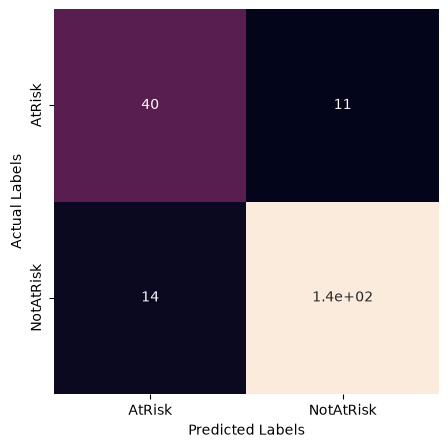

In [23]:
from sklearn.model_selection import train_test_split, cross_validate
from feature_engine.discretisation import DecisionTreeDiscretiser
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OrdinalEncoder
from sklearn.tree import DecisionTreeClassifier
import utils as ad

sd_XX = sd_X.copy()
sd_XX.drop(columns=['student_key', 'exam_result', 'grade'], inplace=True)

# Calculate the configured statistical comparison.
X_train, X_test, y_train, y_test = train_test_split(
    sd_XX, sd_y, test_size=0.2, random_state=43
)

# Apply the existing supervised bin boundaries.
dt_binner = DecisionTreeDiscretiser(
    bin_output='boundaries',
    cv=5,
    precision=2,
    scoring='accuracy',
    regression=False,
    random_state=43,
    param_grid={'max_depth': [3, 5], 'ccp_alpha': [0.0, 0.01, 0.1]}
)

# Fit + transform on train.
X_train_binned = dt_binner.fit_transform(X_train, y_train)
X_test_binned  = dt_binner.transform(X_test)

X_train = pd.DataFrame(X_train_binned)
X_test = pd.DataFrame(X_test_binned)
y_train = pd.Series(y_train)

# Read or prepare the relevant input frame.
cat_cols = X_train.select_dtypes(include=['object']).columns.tolist()

# Display class discrimination across decision thresholds.
cat_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OrdinalEncoder())
])

# Use the established encoding for categorical values or labels.
X_train = pd.DataFrame(cat_pipeline.fit_transform(X_train[cat_cols]), columns=cat_cols)
X_test  = pd.DataFrame(cat_pipeline.transform(X_test[cat_cols]), columns=cat_cols)

clf = DecisionTreeClassifier(random_state=43, class_weight='balanced')

# Train the model.
ad.summarize_stratified_cv(X_train, y_train, clf, cv_=5, print_dict=False)

# Evaluation.
y_pred = clf.predict(X_test)
print(ad.classification_report(y_test, y_pred))
ad.display_confusion_heatmap(y_test, y_pred)

## Compare binning strategies

Evaluate fixed-distribution intervals against decision-tree-derived intervals. Each alternative changes the feature representation rather than the observed labels.


Mean Accuracy is 82.25 +/- 2.04
Mean Precision is 78.54 +/- 2.70
Mean Recall is 78.00 +/- 2.41
Mean F-score is 78.14 +/- 2.29
Best parameters found: {'preprocessor__num__discretizer__n_bins': 5, 'preprocessor__num__discretizer__strategy': 'quantile'}
              precision    recall  f1-score   support

      AtRisk       0.61      0.67      0.64        51
   NotAtRisk       0.88      0.85      0.87       149

    accuracy                           0.81       200
   macro avg       0.74      0.76      0.75       200
weighted avg       0.81      0.81      0.81       200



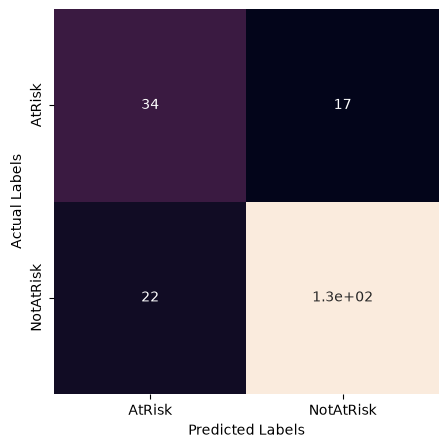

In [24]:
from sklearn.preprocessing import KBinsDiscretizer
from sklearn.model_selection import GridSearchCV

sd_XX = sd_X.copy()
sd_XX.drop(columns=['student_key', 'exam_result', 'grade'], inplace=True)

# Prepare categorical inputs for the estimator.
cat_cols = sd_XX.select_dtypes(include=['object']).columns.tolist()
num_cols = sd_XX.select_dtypes(exclude=['object']).columns.tolist()

# Calculate the configured statistical comparison.
X_train, X_test, y_train, y_test = train_test_split(
    sd_XX, sd_y, test_size=0.2, random_state=43
)

# Fill missing categories using the existing fitted strategy.
cat_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OrdinalEncoder())
])

# Pipeline for numerical columns: discretization with unsupervized kbinsdiscretizer.
num_pipeline = Pipeline(steps=[
    ('discretizer', KBinsDiscretizer(encode='ordinal', strategy='uniform', subsample=None))
])

cat_indices = [sd_XX.columns.get_loc(col) for col in cat_cols]
num_indices = [sd_XX.columns.get_loc(col) for col in num_cols]

# Prepare categorical inputs for the estimator.
preprocessor = ColumnTransformer(transformers=[
    ('cat', cat_pipeline, cat_indices),
    ('num', num_pipeline, num_indices)
])

# Full pipeline with classifier.
pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', DecisionTreeClassifier(class_weight='balanced', random_state=43))
])

# Set up gridsearchcv for kbinsdiscretizer parameters.
param_grid = {
    'preprocessor__num__discretizer__n_bins': [3, 5],
    'preprocessor__num__discretizer__strategy': ['uniform', 'quantile', 'kmeans']
}

# Perform gridsearchcv.
grid_search = GridSearchCV(pipeline, param_grid, cv=5, scoring='accuracy', n_jobs=-1)
grid_search.fit(X_train, y_train)

# Summarize results over the established validation folds.
ad.summarize_stratified_cv(X_train, y_train, grid_search.best_estimator_, cv_=5, print_dict=False)

# Print best parameters and performance.
print(f'Best parameters found: {grid_search.best_params_}')

# Evaluation.
y_pred = grid_search.best_estimator_.predict(X_test)
print(ad.classification_report(y_test, y_pred))
ad.display_confusion_heatmap(y_test, y_pred)

Mean Accuracy is 84.00 +/- 1.79
Mean Precision is 80.63 +/- 2.57
Mean Recall is 80.41 +/- 2.96
Mean F-score is 80.36 +/- 2.41
              precision    recall  f1-score   support

      AtRisk       0.68      0.80      0.74        51
   NotAtRisk       0.93      0.87      0.90       149

    accuracy                           0.85       200
   macro avg       0.81      0.84      0.82       200
weighted avg       0.87      0.85      0.86       200



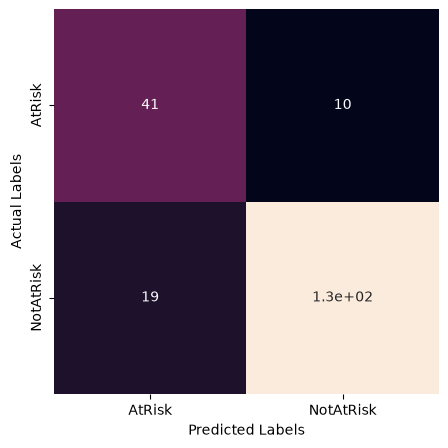

In [25]:
from feature_engine.discretisation import DecisionTreeDiscretiser

sd_XX = sd_X.copy()
sd_XX.drop(columns=['student_key', 'exam_result', 'grade'], inplace=True)

X_train, X_test, y_train, y_test = train_test_split(
    sd_XX, sd_y, test_size=0.2, random_state=43
)

# Apply the existing supervised bin boundaries.
dt_binner = DecisionTreeDiscretiser(
    bin_output='boundaries',
    precision=2,
    scoring='accuracy',
    regression=False,
    random_state=43,
    param_grid={'max_depth': [3, 5], 'ccp_alpha': [0.0, 0.01, 0.1]}
)
# Calculate the configured statistical comparison.
X_train_binned = dt_binner.fit_transform(X_train, y_train)
X_test_binned  = dt_binner.transform(X_test)

X_train = pd.DataFrame(X_train_binned)
X_test = pd.DataFrame(X_test_binned)
y_train = pd.Series(y_train)


# Read or prepare the relevant input frame.
# Fill missing categories using the existing fitted strategy.
# Prepare categorical inputs for the estimator.
cat_cols = X_train.select_dtypes(include=['object']).columns.tolist()

# Display class discrimination across decision thresholds.
preprocessor = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OrdinalEncoder())
])

# Use the established encoding for categorical values or labels.
X_train = pd.DataFrame(preprocessor.fit_transform(X_train[cat_cols]), columns=cat_cols)
X_test  = pd.DataFrame(preprocessor.transform(X_test[cat_cols]), columns=cat_cols)


# Train the model.
clf = DecisionTreeClassifier(random_state=43, class_weight='balanced')
ad.summarize_stratified_cv(X_train, y_train, clf, cv_=5, print_dict=False)

# Evaluation.
y_pred = clf.predict(X_test)
print(ad.classification_report(y_test, y_pred))
ad.display_confusion_heatmap(y_test, y_pred)

### Recorded binning comparison

The saved output reports approximately **82.00%** mean accuracy with the unsupervised discretizer and **84.75%** with the supervised alternative in the corresponding cells. These are validation results from separate preprocessing experiments and should not be confused with the final model's held-out performance.


## Combine related activity measures

Compare standardized combinations with a one-component PCA representation. These experiments retain the source values and introduce a derived coordinate to summarize related activity measures.


Mean Accuracy is 85.25 +/- 2.00
Mean Precision is 82.08 +/- 2.48
Mean Recall is 81.54 +/- 3.08
Mean F-score is 81.76 +/- 2.74
              precision    recall  f1-score   support

      AtRisk       0.72      0.71      0.71        51
   NotAtRisk       0.90      0.91      0.90       149

    accuracy                           0.85       200
   macro avg       0.81      0.81      0.81       200
weighted avg       0.85      0.85      0.85       200



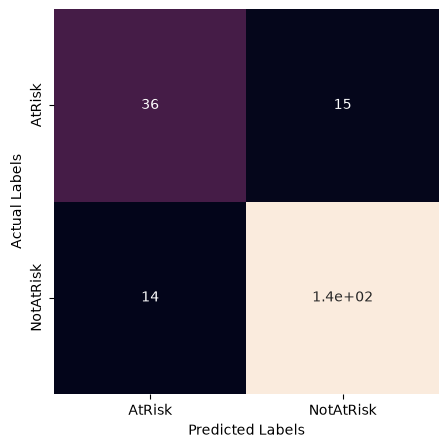

In [26]:
from sklearn.preprocessing import StandardScaler

sd_XX = sd_X.copy()

# Standardize features using training-derived parameters.
scaler = StandardScaler()
scaled = scaler.fit_transform(sd_XX[['social_media_time', 'netflix_viewing_hours']])
sd_XX['z_screen_time'] = scaled[:, 0] + scaled[:, 1]
sd_XX[['social_media_hours_scaled', 'netflix_hours_scaled']] = scaled

# Exclude features outside the current experiment.
sd_XX.drop(columns=[
    'student_key', 'exam_result', 'grade', 'social_media_time', 'netflix_viewing_hours'
], inplace=True)

X_train, X_test, y_train, y_test = train_test_split(
    sd_XX, sd_y, test_size=0.2, random_state=43
)

# Apply the existing supervised bin boundaries.
dt_binner = DecisionTreeDiscretiser(
    bin_output='boundaries',
    cv=5,
    precision=2,
    scoring='accuracy',
    regression=False,
    random_state=43,
    param_grid={'max_depth': [3, 5], 'ccp_alpha': [0.0, 0.01, 0.1]}
)
# Calculate the configured statistical comparison.
X_train_binned = dt_binner.fit_transform(X_train, y_train)
X_test_binned  = dt_binner.transform(X_test)

X_train = pd.DataFrame(X_train_binned)
X_test = pd.DataFrame(X_test_binned)
y_train = pd.Series(y_train)

# Read or prepare the relevant input frame.
# Fill missing categories using the existing fitted strategy.
# Prepare categorical inputs for the estimator.
cat_cols = X_train.select_dtypes(include=['object']).columns.tolist()

# Display class discrimination across decision thresholds.
preprocessor = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OrdinalEncoder())
])

# Use the established encoding for categorical values or labels.
X_train = pd.DataFrame(preprocessor.fit_transform(X_train[cat_cols]), columns=cat_cols)
X_test  = pd.DataFrame(preprocessor.transform(X_test[cat_cols]), columns=cat_cols)

# Train and evaluate the classifier.
clf = DecisionTreeClassifier(random_state=43, class_weight='balanced')
ad.summarize_stratified_cv(X_train, y_train, clf, cv_=5, print_dict=False)
y_pred = clf.predict(X_test)
print(ad.classification_report(y_test, y_pred))
ad.display_confusion_heatmap(y_test, y_pred)

Mean Accuracy is 85.00 +/- 2.24
Mean Precision is 81.87 +/- 2.78
Mean Recall is 81.13 +/- 2.99
Mean F-score is 81.43 +/- 2.84
              precision    recall  f1-score   support

      AtRisk       0.78      0.78      0.78        51
   NotAtRisk       0.93      0.93      0.93       149

    accuracy                           0.89       200
   macro avg       0.86      0.86      0.86       200
weighted avg       0.89      0.89      0.89       200



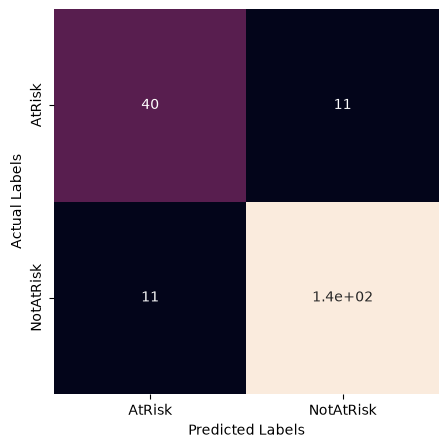

In [ ]:
from sklearn.decomposition import PCA

sd_XX = sd_X.copy()

# Compute the one-component media representation.
pca = PCA(n_components=1)
sd_XX['media_usage_hours_pca'] = pca.fit_transform(sd_XX[['social_media_time', 'netflix_viewing_hours']])

# Exclude features outside the current experiment.
sd_XX.drop(columns=[
    'student_key', 'exam_result', 'grade'
], inplace=True)

# Calculate the configured statistical comparison.
X_train, X_test, y_train, y_test = train_test_split(
    sd_XX, sd_y, test_size=0.2, random_state=43
)

# Apply the existing supervised bin boundaries.
dt_binner = DecisionTreeDiscretiser(
    bin_output='boundaries',
    cv=5,
    precision=2,
    scoring='accuracy',
    regression=False,
    random_state=43,
    param_grid={'max_depth': [3, 5], 'ccp_alpha': [0.0, 0.01, 0.1]}
)

# Read or prepare the relevant input frame.
X_train_binned = dt_binner.fit_transform(X_train, y_train)
X_test_binned = dt_binner.transform(X_test)

X_train = pd.DataFrame(X_train_binned)
X_test = pd.DataFrame(X_test_binned)
y_train = pd.Series(y_train)

# Fill missing categories using the existing fitted strategy.
cat_cols = X_train.select_dtypes(include=['object']).columns.tolist()

# Display class discrimination across decision thresholds.
preprocessor = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OrdinalEncoder())
])

# Use the established encoding for categorical values or labels.
X_train = pd.DataFrame(preprocessor.fit_transform(X_train[cat_cols]), columns=cat_cols)
X_test  = pd.DataFrame(preprocessor.transform(X_test[cat_cols]), columns=cat_cols)

# Train and evaluate the classifier.
clf = DecisionTreeClassifier(random_state=43, class_weight='balanced')
ad.summarize_stratified_cv(X_train, y_train, clf, cv_=5, print_dict=False)
y_pred = clf.predict(X_test)
print(ad.classification_report(y_test, y_pred))
ad.display_confusion_heatmap(y_test, y_pred)

### Aggregation observations

The Z-score feature-combination experiment reports approximately **85.50%** mean accuracy, while the PCA experiment reports approximately **84.88%** in its saved output. The comparison is specific to the chosen pipeline and validation procedure.


## Address the minority class

Compare SMOTE and BorderlineSMOTE with the resampling parameters. Synthetic examples should be generated from training data only; any cross-validation score derived after resampling must be interpreted with care because fold-level separation matters.


Mean Accuracy is 89.23 +/- 1.47
Mean Precision is 89.39 +/- 1.38
Mean Recall is 89.23 +/- 1.47
Mean F-score is 89.22 +/- 1.47
              precision    recall  f1-score   support

      AtRisk       0.63      0.78      0.70        51
   NotAtRisk       0.92      0.85      0.88       149

    accuracy                           0.83       200
   macro avg       0.78      0.81      0.79       200
weighted avg       0.85      0.83      0.84       200



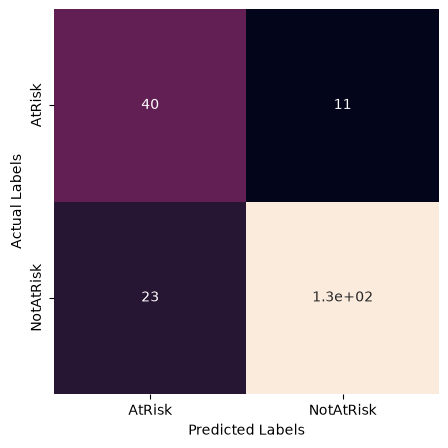

In [28]:
from imblearn.over_sampling import SMOTE

sd_XX = sd_X.copy()

pca = PCA(n_components=1)
sd_XX['media_usage_hours_pca'] = pca.fit_transform(sd_XX[['social_media_time', 'netflix_viewing_hours']])
sd_XX.drop(columns=[
    'student_key', 'exam_result', 'grade'
], inplace=True)

X_train, X_test, y_train, y_test = train_test_split(
    sd_XX, sd_y, test_size=0.2, random_state=43
)

dt_binner = DecisionTreeDiscretiser(
    bin_output='boundaries',
    cv=5,
    precision=2,
    scoring='accuracy',
    regression=False,
    random_state=43,
    param_grid={'max_depth': [3, 5], 'ccp_alpha': [0.0, 0.01, 0.1]}
)

X_train_binned = dt_binner.fit_transform(X_train, y_train)
X_test_binned = dt_binner.transform(X_test)

X_train = pd.DataFrame(X_train_binned)
X_test = pd.DataFrame(X_test_binned)
y_train = pd.Series(y_train)

# Fill missing categories using the existing fitted strategy.
cat_cols = X_train.select_dtypes(include=['object']).columns.tolist()

# Display class discrimination across decision thresholds.
preprocessor = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OrdinalEncoder())
])

# Use the established encoding for categorical values or labels.
X_train = pd.DataFrame(preprocessor.fit_transform(X_train[cat_cols]), columns=cat_cols)
X_test  = pd.DataFrame(preprocessor.transform(X_test[cat_cols]), columns=cat_cols)


# Balance the training partition with the configured sampler.
smote = SMOTE(random_state=43)
X_train, y_train = smote.fit_resample(X_train, y_train)

# Train and evaluate the classifier.
clf = DecisionTreeClassifier(random_state=43)
ad.summarize_stratified_cv(X_train, y_train, clf, cv_=5, print_dict=False)
y_pred = clf.predict(X_test)
print(ad.classification_report(y_test, y_pred))
ad.display_confusion_heatmap(y_test, y_pred)

Mean Accuracy is 90.28 +/- 2.16
Mean Precision is 90.33 +/- 2.17
Mean Recall is 90.29 +/- 2.16
Mean F-score is 90.28 +/- 2.16
              precision    recall  f1-score   support

      AtRisk       0.73      0.78      0.75        51
   NotAtRisk       0.92      0.90      0.91       149

    accuracy                           0.87       200
   macro avg       0.83      0.84      0.83       200
weighted avg       0.87      0.87      0.87       200



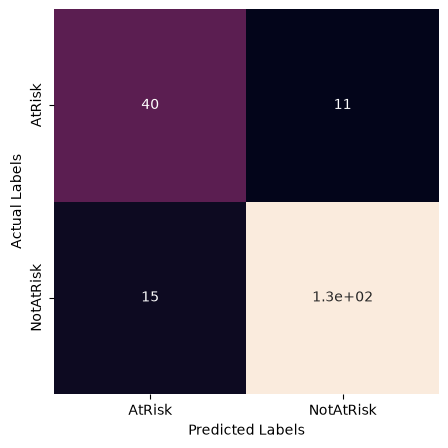

In [29]:
from imblearn.over_sampling import BorderlineSMOTE

sd_XX = sd_X.copy()
pca = PCA(n_components=1)
sd_XX['media_usage_hours_pca'] = pca.fit_transform(sd_XX[['social_media_time', 'netflix_viewing_hours']])

sd_XX.drop(columns=[
    'student_key', 'exam_result', 'grade'
], inplace=True)

X_train, X_test, y_train, y_test = train_test_split(
    sd_XX, sd_y, test_size=0.2, random_state=43
)

dt_binner = DecisionTreeDiscretiser(
    bin_output='boundaries',
    cv=5,
    precision=2,
    scoring='accuracy',
    regression=False,
    random_state=43,
    param_grid={'max_depth': [3, 5], 'ccp_alpha': [0.0, 0.01, 0.1]}
)

X_train_binned = dt_binner.fit_transform(X_train, y_train)
X_test_binned = dt_binner.transform(X_test)

X_train = pd.DataFrame(X_train_binned)
X_test = pd.DataFrame(X_test_binned)
y_train = pd.Series(y_train)

# Fill missing categories using the existing fitted strategy.
cat_cols = X_train.select_dtypes(include=['object']).columns.tolist()

preprocessor = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OrdinalEncoder())
])

# Use the established encoding for categorical values or labels.
X_train = pd.DataFrame(preprocessor.fit_transform(X_train[cat_cols]), columns=cat_cols)
X_test  = pd.DataFrame(preprocessor.transform(X_test[cat_cols]), columns=cat_cols)

# Balance the training partition with the configured sampler.
smote = BorderlineSMOTE(random_state=43, k_neighbors=3, m_neighbors=3)
X_train, y_train = smote.fit_resample(X_train, y_train)

# Train and evaluate the classifier.
clf = DecisionTreeClassifier(random_state=43)
ad.summarize_stratified_cv(X_train, y_train, clf, cv_=5, print_dict=False)
y_pred = clf.predict(X_test)
print(ad.classification_report(y_test, y_pred))
ad.display_confusion_heatmap(y_test, y_pred)

### Resampling results

The saved runs report approximately **90.28%** mean accuracy with SMOTE and **91.07%** with BorderlineSMOTE in their respective experiments. These results describe the selected resampled validation procedures, **not** a new untouched test set. Class imbalance and validation ordering both affect the interpretation.


## Control tree complexity

A larger decision tree can fit training observations closely without improving unseen-case performance. Inspect depth and leaf counts before exploring constrained search spaces.


In [30]:
clf.get_depth(), clf.get_n_leaves()

(11, np.int64(84))

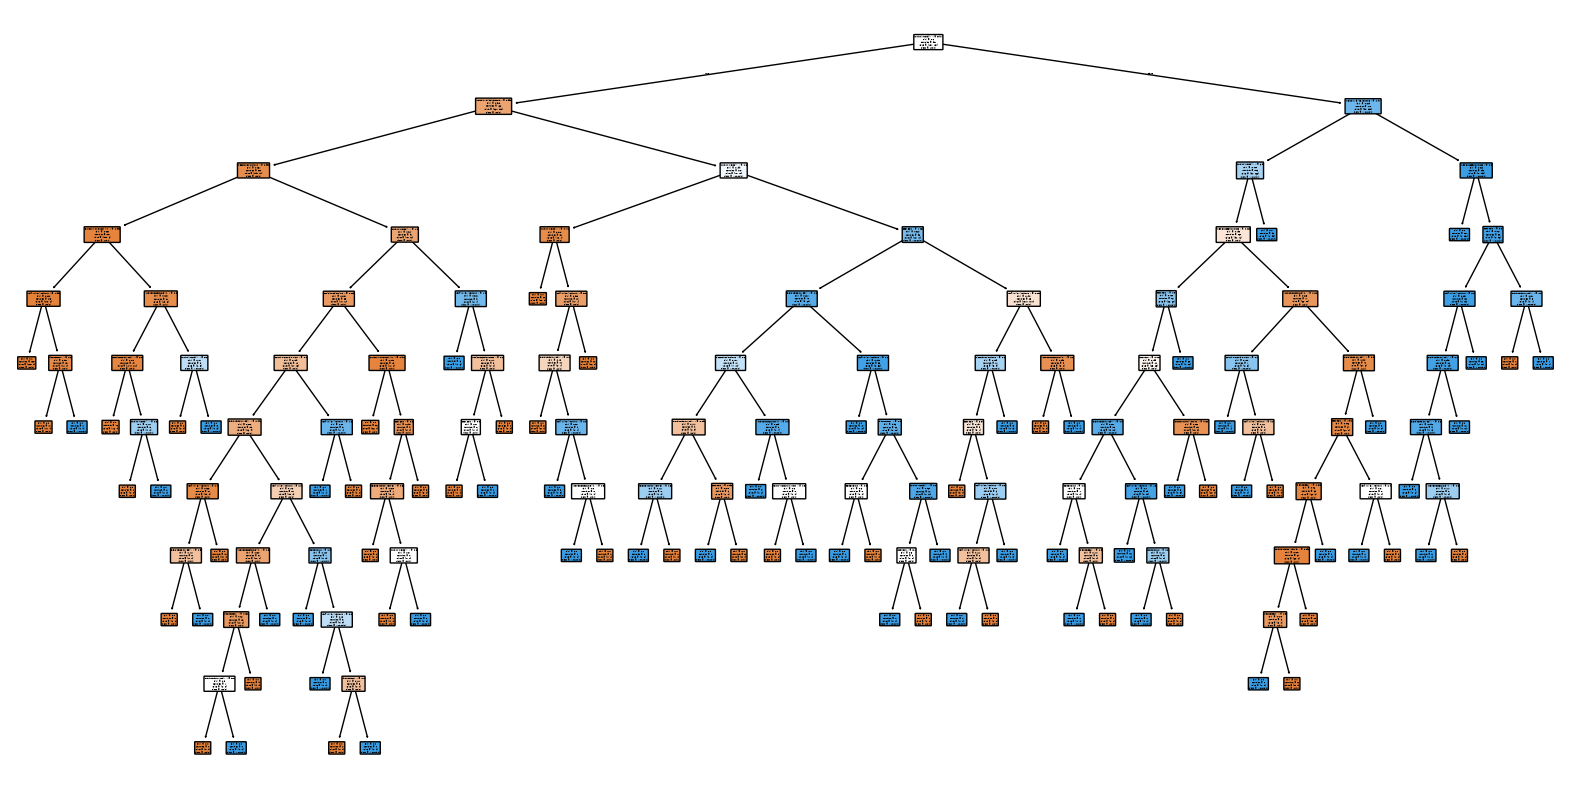

In [31]:
# Visualize the pruned decision tree.
plt.figure(figsize=(20, 10))  # Adjust the size if necessary.
plot_tree(
    clf, 
    filled=True, 
    feature_names=X_train.columns, 
    class_names=clf.classes_.astype(str),  # Ensure class names are in string format.
    rounded=True
)
plt.show()

## Tune pruning and split constraints

Explore depth, minimum split size, leaf size and pruning controls using the existing randomized-search configuration. Compare tree size against the reported validation metrics.


Best parameters found: {'splitter': 'best', 'min_samples_split': 4, 'min_samples_leaf': 2, 'min_impurity_decrease': np.float64(0.03), 'max_depth': 9, 'criterion': 'entropy', 'ccp_alpha': 0.003}
Mean Accuracy is 88.53 +/- 3.33
Mean Precision is 88.79 +/- 3.39
Mean Recall is 88.53 +/- 3.33
Mean F-score is 88.51 +/- 3.33
              precision    recall  f1-score   support

      AtRisk       0.67      0.84      0.75        51
   NotAtRisk       0.94      0.86      0.90       149

    accuracy                           0.85       200
   macro avg       0.81      0.85      0.82       200
weighted avg       0.87      0.85      0.86       200



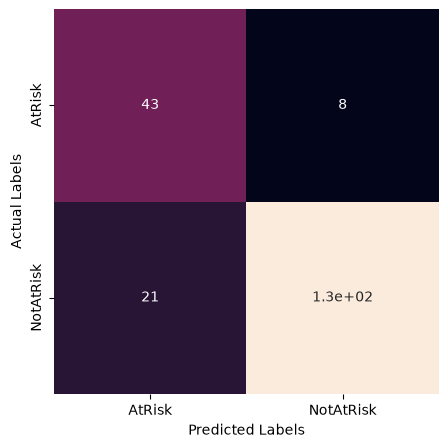

In [ ]:
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import uniform

sd_XX = sd_X.copy()
pca = PCA(n_components=1)
sd_XX['media_usage_hours_pca'] = pca.fit_transform(sd_XX[['social_media_time', 'netflix_viewing_hours']])

sd_XX.drop(columns=[
    'student_key', 'exam_result', 'grade'
], inplace=True)

X_train, X_test, y_train, y_test = train_test_split(
    sd_XX, sd_y, test_size=0.2, random_state=43
)

dt_binner = DecisionTreeDiscretiser(
    bin_output='boundaries',
    cv=5,
    precision=2,
    scoring='accuracy',
    regression=False,
    random_state=43,
    param_grid={'max_depth': [3, 5], 'ccp_alpha': [0.0, 0.01, 0.1]}
)

X_train_binned = dt_binner.fit_transform(X_train, y_train)
X_test_binned = dt_binner.transform(X_test)

X_train = pd.DataFrame(X_train_binned)
X_test = pd.DataFrame(X_test_binned)
y_train = pd.Series(y_train)

# Fill missing categories using the existing fitted strategy.
cat_cols = X_train.select_dtypes(include=['object']).columns.tolist()

preprocessor = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OrdinalEncoder())
])

# Use the established encoding for categorical values or labels.
X_train = pd.DataFrame(preprocessor.fit_transform(X_train[cat_cols]), columns=cat_cols)
X_test  = pd.DataFrame(preprocessor.transform(X_test[cat_cols]), columns=cat_cols)

# Balance the training partition with the configured sampler.
smote = BorderlineSMOTE(random_state=43, k_neighbors=3, m_neighbors=3)
X_train, y_train = smote.fit_resample(X_train, y_train)

# Train and evaluate the classifier.
# Search the hyperparameter candidates.
params_dist = {
    'splitter': ['best', 'random'],
    'criterion' : ['gini', 'entropy'],
    'max_depth': range(3, 11),
    'min_impurity_decrease' : np.arange(0.01, 0.3, 0.01),
    'min_samples_leaf': range(2, 20, 4),
    'min_samples_split': range(2, 10, 2),
    'ccp_alpha': [0.003, 0.005, 0.007]
}
# Define the base decisiontreeclassifier.
clf = DecisionTreeClassifier(random_state=43)

# Search the hyperparameter candidates.
random_search = RandomizedSearchCV(
    clf,
    param_distributions=params_dist,
    n_iter=100,  # Number of random parameter combinations to try.
    cv=5,  # Summarize results over the established validation folds.
    random_state=43,
    n_jobs=-1,
    scoring='accuracy'
)

# Search the hyperparameter candidates.
random_search.fit(X_train, y_train)

# Print best parameters and performance.
print(f'Best parameters found: {random_search.best_params_}')

# Train and evaluate the classifier.
best_clf = random_search.best_estimator_
ad.summarize_stratified_cv(X_train, y_train, best_clf, cv_=5, print_dict=False)
y_pred = best_clf.predict(X_test)
print(ad.classification_report(y_test, y_pred))
ad.display_confusion_heatmap(y_test, y_pred)

In [33]:
best_clf.get_depth(), best_clf.get_n_leaves()

(4, np.int64(7))

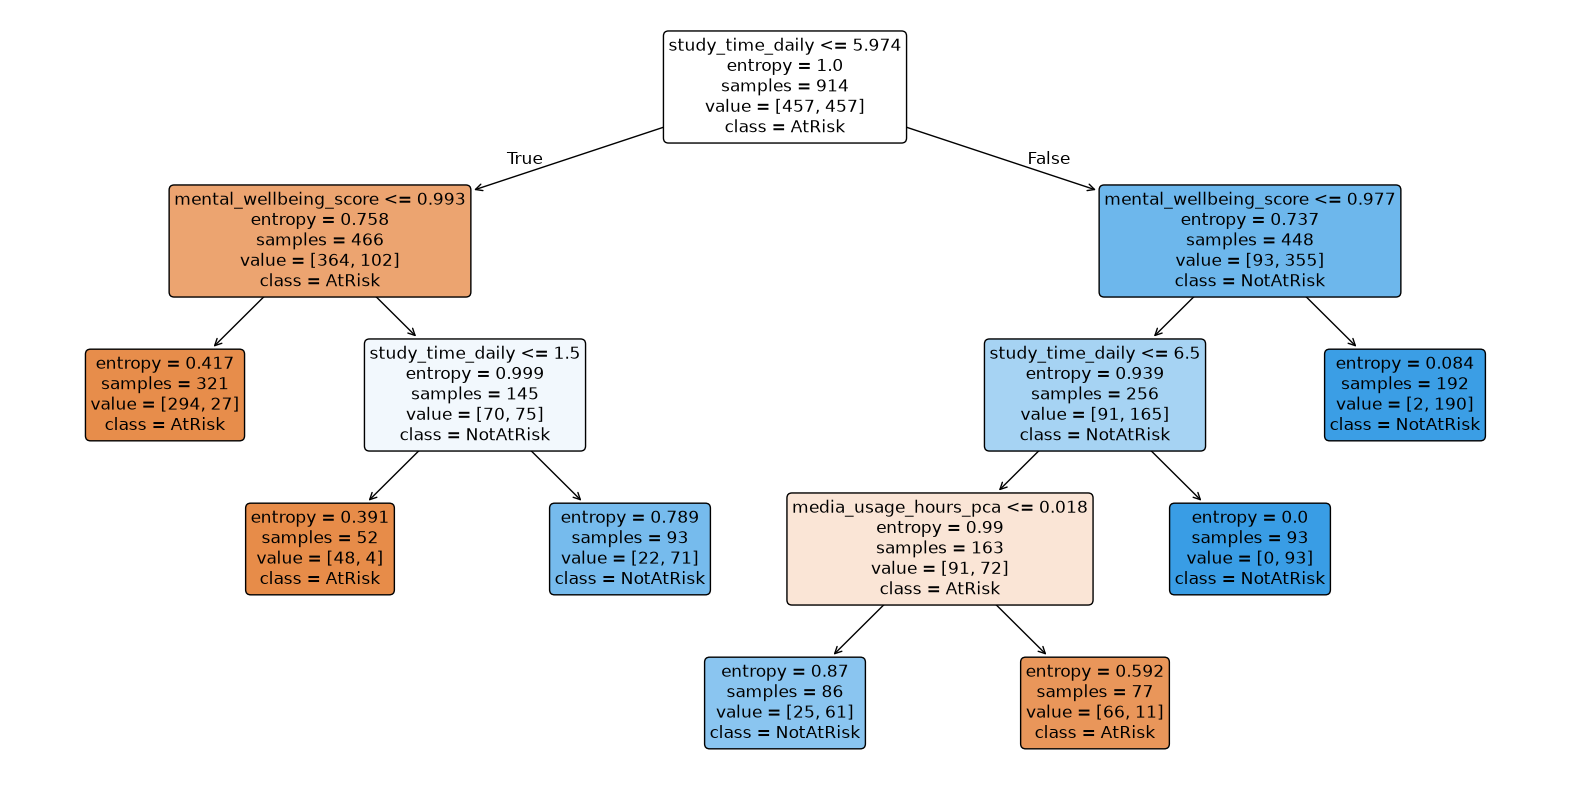

In [34]:
# Visualize the pruned decision tree.
plt.figure(figsize=(20, 10))  # Adjust the size if necessary.
plot_tree(
    best_clf, 
    filled=True, 
    feature_names=X_train.columns, 
    class_names=best_clf.classes_.astype(str),  # Ensure class names are in string format.
    rounded=True
)
plt.show()

### Interpreting the trade-off

Smaller trees may offer clearer rules at the cost of lower predictive scores. The aim is a transparent balance between complexity and generalization, rather than maximizing a single cross-validation estimate.


## Embedded feature selection and combined preparation

Use estimator-based feature importance to reduce the candidate predictor set. The following cells retain the PCA, binning, resampling and tuning sequence so that results can be compared directly with the reference notebook.


Best parameters found: {'splitter': 'best', 'min_samples_split': 8, 'min_samples_leaf': 2, 'min_impurity_decrease': np.float64(0.01), 'max_depth': 9, 'criterion': 'entropy', 'ccp_alpha': 0.007}
Mean Accuracy is 89.49 +/- 2.18
Mean Precision is 89.75 +/- 2.03
Mean Recall is 89.49 +/- 2.18
Mean F-score is 89.47 +/- 2.19
              precision    recall  f1-score   support

      AtRisk       0.66      0.88      0.76        51
   NotAtRisk       0.95      0.85      0.90       149

    accuracy                           0.85       200
   macro avg       0.81      0.86      0.83       200
weighted avg       0.88      0.85      0.86       200



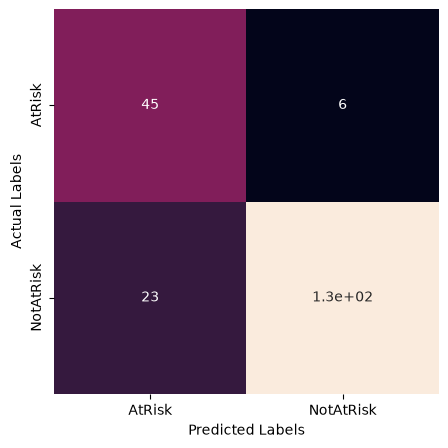

In [ ]:
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold

sd_XX = sd_X.copy()
pca = PCA(n_components=1)
sd_XX['media_usage_hours_pca'] = pca.fit_transform(sd_XX[['social_media_time', 'netflix_viewing_hours']])

sd_XX.drop(columns=[
    'student_key', 'exam_result', 'grade'
], inplace=True)

X_train, X_test, y_train, y_test = train_test_split(
    sd_XX, sd_y, test_size=0.2, random_state=43
)

dt_binner = DecisionTreeDiscretiser(
    bin_output='boundaries',
    cv=5,
    precision=2,
    scoring='accuracy',
    regression=False,
    random_state=43,
    param_grid={'max_depth': [3, 5], 'ccp_alpha': [0.0, 0.01, 0.1]}
)

X_train_binned = dt_binner.fit_transform(X_train, y_train)
X_test_binned = dt_binner.transform(X_test)

X_train = pd.DataFrame(X_train_binned)
X_test = pd.DataFrame(X_test_binned)
y_train = pd.Series(y_train)

cat_cols = X_train.select_dtypes(include=['object']).columns.tolist()

preprocessor = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OrdinalEncoder())
])

# Use the established encoding for categorical values or labels.
X_train = pd.DataFrame(preprocessor.fit_transform(X_train[cat_cols]), columns=cat_cols)
X_test  = pd.DataFrame(preprocessor.transform(X_test[cat_cols]), columns=cat_cols)

# Balance the training partition with the configured sampler.
smote = BorderlineSMOTE(random_state=43, k_neighbors=3, m_neighbors=3)
X_train, y_train = smote.fit_resample(X_train, y_train)

# Standardize features using training-derived parameters.
scaler = StandardScaler()
X_train = pd.DataFrame(scaler.fit_transform(X_train), columns=cat_cols)
X_test = pd.DataFrame(scaler.transform(X_test), columns=cat_cols)

# Summarize results over the established validation folds.
stratified_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=43)

# Train and evaluate the classifier.
# Search the hyperparameter candidates.
params_dist = {
    'splitter': ['best', 'random'],
    'criterion' : ['gini', 'entropy'],
    'max_depth': range(3, 11),
    'min_impurity_decrease' : np.arange(0.01, 0.3, 0.01),
    'min_samples_leaf': range(2, 20, 4),
    'min_samples_split': range(2, 10, 2),
    'ccp_alpha': [0.003, 0.005, 0.007]
}
# Define the base decisiontreeclassifier.
clf = DecisionTreeClassifier(random_state=43)

# Search the hyperparameter candidates.
random_search = RandomizedSearchCV(
    clf,
    param_distributions=params_dist,
    n_iter=100,  # Number of random parameter combinations to try.
    cv=stratified_cv,
    random_state=43,
    n_jobs=-1,
    scoring='accuracy'
)

# Search the hyperparameter candidates.
random_search.fit(X_train, y_train)

# Print best parameters and performance.
print(f'Best parameters found: {random_search.best_params_}')

# Train and evaluate the classifier.
best_clf = random_search.best_estimator_
ad.summarize_stratified_cv(X_train, y_train, best_clf, cv_=5, print_dict=False)
y_pred = best_clf.predict(X_test)
print(ad.classification_report(y_test, y_pred))
ad.display_confusion_heatmap(y_test, y_pred)

['age_years', 'attendance_rate', 'diet_category', 'exercise_days_weekly', 'extracurricular_activity', 'gender_group', 'internet_access_quality', 'mental_wellbeing_score', 'netflix_viewing_hours', 'parental_schooling_tier', 'part_time_employment', 'sleep_duration_hours', 'social_media_time', 'study_time_daily', 'media_usage_hours_pca'] 15
Best parameters found: {'ccp_alpha': np.float64(0.008462226447329869), 'criterion': 'entropy', 'max_depth': 9, 'min_impurity_decrease': np.float64(0.01), 'min_samples_leaf': 6, 'min_samples_split': 6, 'splitter': 'best'}
Mean Accuracy is 89.14 +/- 1.74
Mean Precision is 89.46 +/- 1.60
Mean Recall is 89.14 +/- 1.74
Mean F-score is 89.12 +/- 1.76
              precision    recall  f1-score   support

      AtRisk       0.64      0.86      0.73        51
   NotAtRisk       0.95      0.83      0.89       149

    accuracy                           0.84       200
   macro avg       0.79      0.85      0.81       200
weighted avg       0.87      0.84      0.

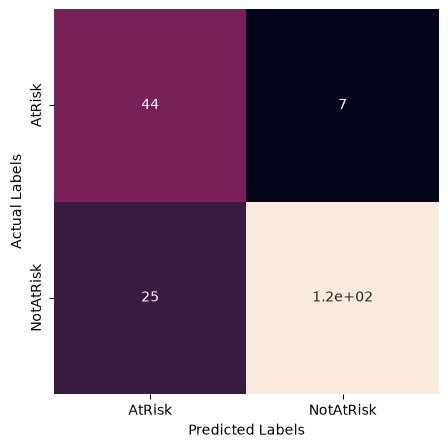

In [ ]:
from sklearn.feature_selection import SelectFromModel
from sklearn.ensemble import RandomForestClassifier 

sd_XX = sd_X.copy()
pca = PCA(n_components=1)
sd_XX['media_usage_hours_pca'] = pca.fit_transform(sd_XX[['social_media_time', 'netflix_viewing_hours']])

sd_XX.drop(columns=[
    'student_key', 'exam_result', 'grade'
], inplace=True)

X_train, X_test, y_train, y_test = train_test_split(
    sd_XX, sd_y, test_size=0.2, random_state=43
)

dt_binner = DecisionTreeDiscretiser(
    bin_output='boundaries',
    cv=5,
    precision=2,
    scoring='accuracy',
    regression=False,
    random_state=43,
    param_grid={'max_depth': [3, 5], 'ccp_alpha': [0.0, 0.01, 0.1]}
)

X_train_binned = dt_binner.fit_transform(X_train, y_train)
X_test_binned = dt_binner.transform(X_test)

X_train = pd.DataFrame(X_train_binned)
X_test = pd.DataFrame(X_test_binned)
y_train = pd.Series(y_train)

cat_cols = X_train.select_dtypes(include=['object']).columns.tolist()

preprocessor = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OrdinalEncoder())
])

# Use the established encoding for categorical values or labels.
X_train = pd.DataFrame(preprocessor.fit_transform(X_train[cat_cols]), columns=cat_cols)
X_test  = pd.DataFrame(preprocessor.transform(X_test[cat_cols]), columns=cat_cols)

# Balance the training partition with the configured sampler.
smote = BorderlineSMOTE(random_state=43, k_neighbors=3, m_neighbors=5)
X_train, y_train = smote.fit_resample(X_train, y_train)

# Standardize features using training-derived parameters.
scaler = StandardScaler()
X_train = pd.DataFrame(scaler.fit_transform(X_train), columns=cat_cols)
X_test = pd.DataFrame(scaler.transform(X_test), columns=cat_cols)

# Select the model-ranked input subset.
selector_estimator = DecisionTreeClassifier(max_depth=8, min_samples_split=5, min_samples_leaf=18, ccp_alpha=0.007,random_state=43)
sfm = SelectFromModel(estimator=selector_estimator, threshold='median')
X_train_selected = sfm.fit_transform(X_train, y_train)
X_test_selected = sfm.transform(X_test)
selected_features = [cat_cols[index] for index in sfm.get_support(indices=True)]
print(selected_features, len(selected_features))
X_train = pd.DataFrame(X_train_selected, columns=selected_features)
X_test = pd.DataFrame(X_test_selected, columns=selected_features)

# Summarize results over the established validation folds.
stratified_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=43)

# Train and evaluate the classifier.
# Search the hyperparameter candidates.
params_dist = {
    'splitter': ['best', 'random'],
    'criterion' : ['gini', 'entropy'],
    'max_depth': range(3, 11),
    'min_impurity_decrease' : np.arange(0.01, 0.3, 0.01),
    'min_samples_leaf': range(2, 20, 4),
    'min_samples_split': range(2, 10, 2),
    'ccp_alpha': uniform(loc=0.005, scale=0.004)
}
# Define the base decisiontreeclassifier.
clf = DecisionTreeClassifier(random_state=43)

# Search the hyperparameter candidates.
random_search = RandomizedSearchCV(
    clf,
    param_distributions=params_dist,
    n_iter=500,  # Number of random parameter combinations to try.
    cv=stratified_cv,
    random_state=43,
    n_jobs=-1,
    scoring='accuracy'
)

# Search the hyperparameter candidates.
random_search.fit(X_train, y_train)

# Print best parameters and performance.
print(f'Best parameters found: {random_search.best_params_}')

# Train and evaluate the classifier.
best_clf = random_search.best_estimator_
ad.summarize_stratified_cv(X_train, y_train, best_clf, cv_=5, print_dict=False)
y_pred = best_clf.predict(X_test)
print(ad.classification_report(y_test, y_pred))
ad.display_confusion_heatmap(y_test, y_pred)

In [37]:
best_clf.get_depth(), best_clf.get_n_leaves()

(6, np.int64(14))

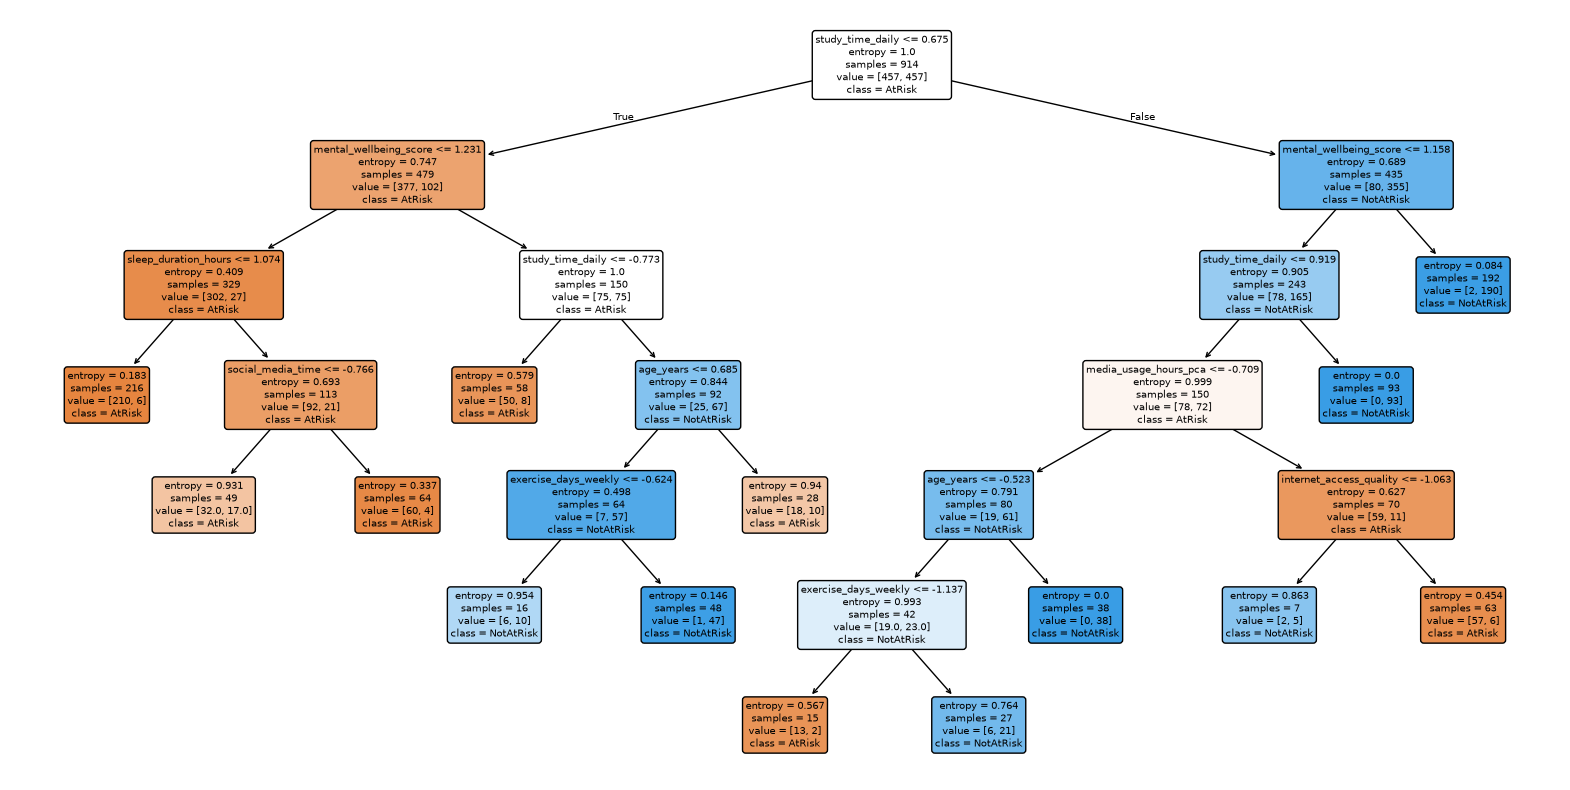

In [38]:
# Visualize the pruned decision tree.
plt.figure(figsize=(20, 10))  # Adjust the size if necessary.
plot_tree(
    best_clf, 
    filled=True, 
    feature_names=X_train.columns, 
    class_names=best_clf.classes_.astype(str),  # Ensure class names are in string format.
    rounded=True
)
plt.show()

Best parameters found: {'ccp_alpha': np.float64(0.006731623306267057), 'criterion': 'entropy', 'max_depth': 6, 'min_impurity_decrease': np.float64(0.005), 'min_samples_leaf': 6, 'min_samples_split': 8, 'splitter': 'best'}
Mean Accuracy is 89.76 +/- 1.40
Mean Precision is 90.02 +/- 1.44
Mean Recall is 89.76 +/- 1.41
Mean F-score is 89.74 +/- 1.41
              precision    recall  f1-score   support

      AtRisk       0.71      0.86      0.77        56
   NotAtRisk       0.94      0.86      0.90       144

    accuracy                           0.86       200
   macro avg       0.82      0.86      0.84       200
weighted avg       0.87      0.86      0.86       200



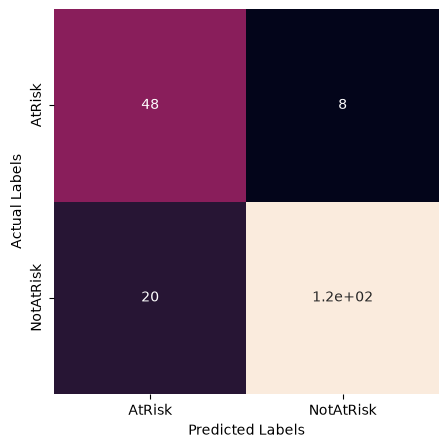

In [ ]:
# Construct the additional model inputs.
sd_XX = sd_X.copy()
pca = PCA(n_components=1)
sd_XX['media_usage_hours_pca'] = pca.fit_transform(sd_XX[['social_media_time', 'netflix_viewing_hours']])
sd_XX.drop(columns=['student_key', 'exam_result', 'grade'], inplace=True)

# Retain the stratified holdout split.
X_train, X_test, y_train, y_test = train_test_split(
    sd_XX, sd_y, test_size=0.2, random_state=43, stratify=sd_y
)

# Better discretization settings: more robust grid.
dt_binner = DecisionTreeDiscretiser(
    bin_output='boundaries',
    cv=5,
    precision=2,
    scoring='accuracy',
    regression=False,
    random_state=43,
    param_grid={'max_depth': [3, 4, 5, 6], 'ccp_alpha': [0.0, 0.005, 0.01]}
)

# Apply discretization.
X_train_binned = dt_binner.fit_transform(X_train, y_train)
X_test_binned = dt_binner.transform(X_test)
X_train = pd.DataFrame(X_train_binned)
X_test = pd.DataFrame(X_test_binned)
y_train = pd.Series(y_train)

# Prepare categorical inputs for the estimator.
cat_cols = X_train.select_dtypes(include=['object']).columns.tolist()
preprocessor = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1))
])
X_train = pd.DataFrame(preprocessor.fit_transform(X_train[cat_cols]), columns=cat_cols)
X_test  = pd.DataFrame(preprocessor.transform(X_test[cat_cols]), columns=cat_cols)

# Balance the training partition with the configured sampler.
smote = BorderlineSMOTE(random_state=43, k_neighbors=5, m_neighbors=10)
X_train, y_train = smote.fit_resample(X_train, y_train)

# Standardize features using training-derived parameters.
scaler = StandardScaler()
X_train = pd.DataFrame(scaler.fit_transform(X_train), columns=cat_cols)
X_test = pd.DataFrame(scaler.transform(X_test), columns=cat_cols)

# Select the model-ranked input subset.
selector_estimator = DecisionTreeClassifier(max_depth=7, min_samples_split=4,
                                            min_samples_leaf=10, ccp_alpha=0.007,
                                            random_state=43)
sfm = SelectFromModel(estimator=selector_estimator, threshold='median')
X_train_selected = sfm.fit_transform(X_train, y_train)
X_test_selected = sfm.transform(X_test)
selected_features = [cat_cols[index] for index in sfm.get_support(indices=True)]
X_train = pd.DataFrame(X_train_selected, columns=selected_features)
X_test = pd.DataFrame(X_test_selected, columns=selected_features)

# Summarize results over the established validation folds.
stratified_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=43)

# Extended search space for better tuning.
params_dist = {
    'splitter': ['best'],
    'criterion': ['gini', 'entropy'],
    'max_depth': range(5, 7),
    'min_impurity_decrease': np.linspace(0.005, 0.05, 10),
    'min_samples_leaf': range(4, 16, 2),
    'min_samples_split': range(4, 12, 2),
    'ccp_alpha': uniform(loc=0.005, scale=0.004)
}
clf = DecisionTreeClassifier(random_state=43)
random_search = RandomizedSearchCV(
    clf,
    param_distributions=params_dist,
    n_iter=300,
    cv=stratified_cv,
    random_state=43,
    n_jobs=-1,
    scoring='accuracy'
)
random_search.fit(X_train, y_train)

# Evaluate best classifier.
print(f'Best parameters found: {random_search.best_params_}')
best_clf = random_search.best_estimator_

# Evaluation.
ad.summarize_stratified_cv(X_train, y_train, best_clf, cv_=5, print_dict=False)
y_pred = best_clf.predict(X_test)
print(ad.classification_report(y_test, y_pred))
ad.display_confusion_heatmap(y_test, y_pred)

In [41]:
best_clf.get_depth(), best_clf.get_n_leaves()

(6, np.int64(22))

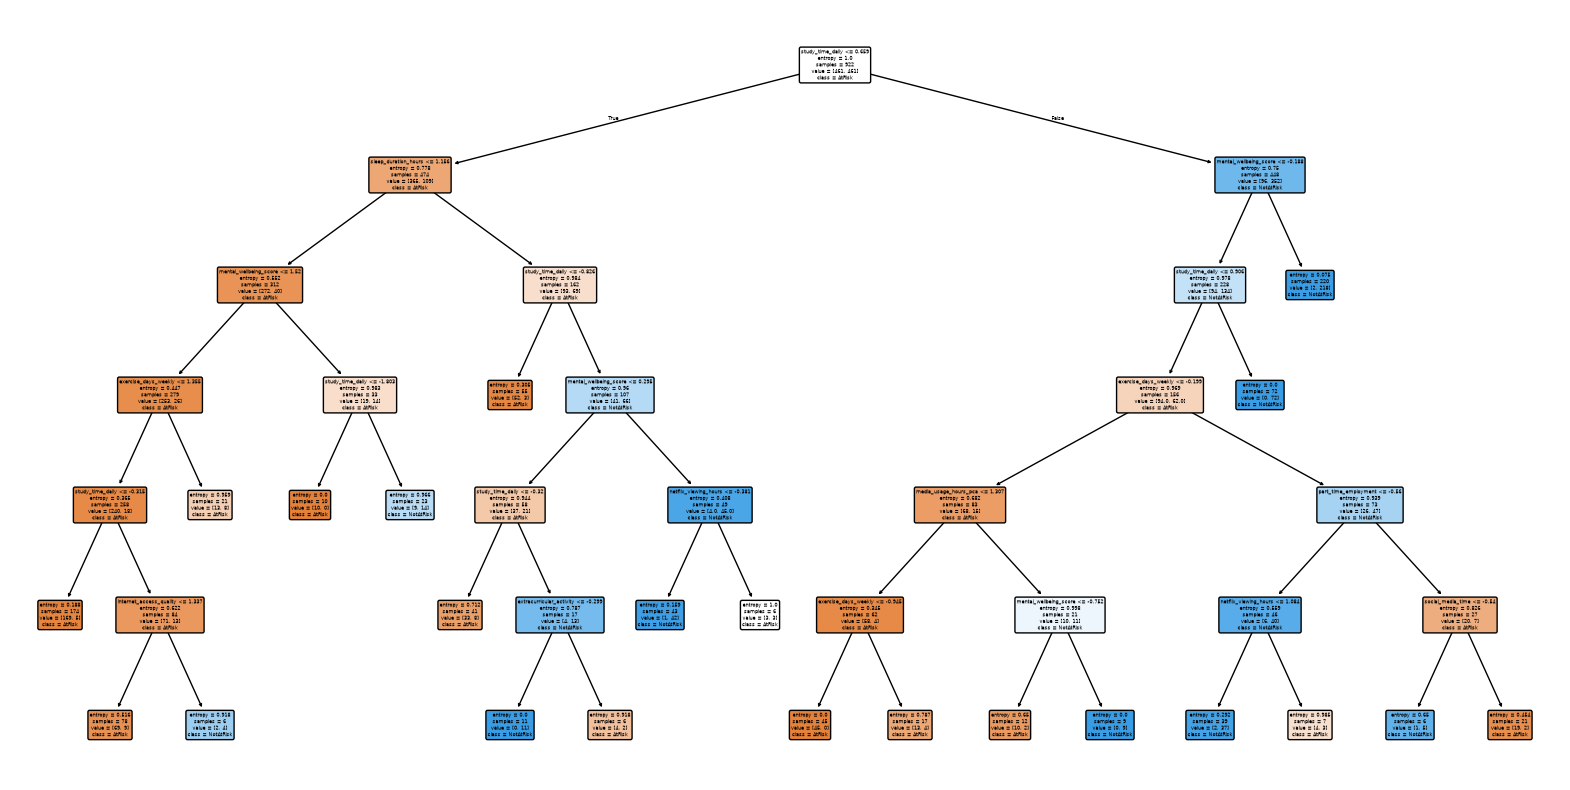

In [42]:
# Visualize the pruned decision tree.
plt.figure(figsize=(20, 10))  # Adjust the size if necessary.
plot_tree(
    best_clf, 
    filled=True, 
    feature_names=X_train.columns, 
    class_names=best_clf.classes_.astype(str),  # Ensure class names are in string format.
    rounded=True
)
plt.show()